# Water Level Forecasting using Random Forest

This notebook implements an end-to-end Machine Learning pipeline for water level prediction using **Random Forest**:
- **Dataset:** Bassac River Water Level (15-minute intervals)
- **Feature Engineering:** Lag features, rolling mean/std, differences, calendar features
- **Target:** 1-hour lead time ()
- **Model:**  from 


## Step 1 — Load and Preprocess Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset (15-minute frequency)
csv_file = "Bassac_01_train.csv"
df = pd.read_csv(csv_file)

# Parse datetime and sort chronologically
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
df = df.sort_values("Date").reset_index(drop=True)

print(f"Data shape: {df.shape}")
df.head()

Data shape: (54606, 2)


,Date,WL
0,2020-06-19 12:00:00,1.18
1,2020-06-19 12:15:00,1.16
2,2020-06-19 12:30:00,1.14
3,2020-06-19 12:45:00,1.12
4,2020-06-19 13:00:00,1.10


## Step 2 — Target Variable ()
Since data is sampled every **15 minutes**:
- **1-hour lead:** 4 steps ahead ()
- *(Optional) 6-hour lead: 24 steps ahead ()*

In [2]:
# Target: Water level 1 hour in the future (4 steps ahead)
df["water_level_lead_1h"] = df["WL"].shift(-4)
df[["Date", "WL", "water_level_lead_1h"]].head(8)

,Date,WL,water_level_lead_1h
0,2020-06-19 12:00:00,1.18,1.10
1,2020-06-19 12:15:00,1.16,1.08
2,2020-06-19 12:30:00,1.14,1.08
3,2020-06-19 12:45:00,1.12,1.07
4,2020-06-19 13:00:00,1.10,1.05
5,2020-06-19 13:15:00,1.08,1.04
6,2020-06-19 13:30:00,1.08,1.02
7,2020-06-19 13:45:00,1.07,1.01


## Step 3 — Feature Engineering ()
- **Lags:** 1h (), 2h (), 6h (), 24h ()
- **Rolling:** 3h mean (12 steps), 12h mean (48 steps), 6h std (24 steps)
- **Difference:** 1h diff ()
- **Calendar:** hour, month, day_of_year

In [3]:
# 1. Lag Features
df["lag_1h"] = df["WL"].shift(4)
df["lag_2h"] = df["WL"].shift(8)
df["lag_6h"] = df["WL"].shift(24)
df["lag_24h"] = df["WL"].shift(96)

# 2. Rolling Statistics
df["roll_mean_3h"] = df["WL"].rolling(window=12).mean()
df["roll_mean_12h"] = df["WL"].rolling(window=48).mean()
df["roll_std_6h"] = df["WL"].rolling(window=24).std()

# 3. Difference (rate of change)
df["diff_1h"] = df["WL"].diff(4)

# 4. Calendar Features
df["hour"] = df["Date"].dt.hour
df["month"] = df["Date"].dt.month
df["day_of_year"] = df["Date"].dt.dayofyear

df.tail()

,Date,WL,water_level_lead_1h,lag_1h,lag_2h,lag_6h,lag_24h,roll_mean_3h,roll_mean_12h,roll_std_6h,diff_1h,hour,month,day_of_year
54601,2022-04-26 22:45:00,1.50,1.45,1.54,1.50,1.05,1.61,1.504167,1.141667,0.145443,-0.04,22,4,116
54602,2022-04-26 23:00:00,1.49,NaN,1.54,1.51,1.09,1.60,1.509167,1.150833,0.132731,-0.05,23,4,116
54603,2022-04-26 23:15:00,1.47,NaN,1.53,1.53,1.13,1.59,1.510833,1.159792,0.120214,-0.06,23,4,116
54604,2022-04-26 23:30:00,1.46,NaN,1.51,1.54,1.17,1.58,1.510000,1.168958,0.108620,-0.05,23,4,116
54605,2022-04-26 23:45:00,1.45,NaN,1.50,1.54,1.19,1.56,1.505833,1.178333,0.096300,-0.05,23,4,116


## Step 4 — Temporal Train/Test Split
- Drop rows containing NaN (from lag/lead operations)
- **Drop timestamp (Tue Sep 29 14:45:17 +07 2026) before model fitting**
- Chronological split (80% train, 20% test) to avoid future data leakage

In [4]:
df_clean = df.dropna().reset_index(drop=True)

# Feature columns (Date dropped)
feature_cols = [
    "WL",            # Current water level at time t
    "lag_1h", "lag_2h", "lag_6h", "lag_24h",
    "roll_mean_3h", "roll_mean_12h",
    "roll_std_6h",
    "diff_1h",
    "hour", "month", "day_of_year"
]
target_col = "water_level_lead_1h"

split_idx = int(len(df_clean) * 0.8)
train = df_clean.iloc[:split_idx]
test = df_clean.iloc[split_idx:]

X_train = train[feature_cols]
y_train = train[target_col]
X_test = test[feature_cols]
y_test = test[target_col]
dates_test = test["Date"]

print(f"Train size: {len(X_train)} rows")
print(f"Test size:  {len(X_test)} rows")

Train size: 43604 rows
Test size:  10902 rows


## Step 5 — Train Random Forest Regressor

In [5]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_split=5,
    n_jobs=-1,
    random_state=42
)

print("Training Random Forest...")
rf_model.fit(X_train, y_train)
print("Training complete!")

Training Random Forest...
Training complete!


## Step 6 — Model Evaluation

In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

rf_preds = rf_model.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))
rf_mae = mean_absolute_error(y_test, rf_preds)
rf_r2 = r2_score(y_test, rf_preds)

print("=== Random Forest Performance on Test Set ===")
print(f"RMSE : {rf_rmse:.4f}")
print(f"MAE  : {rf_mae:.4f}")
print(f"R²   : {rf_r2:.4f}")

=== Random Forest Performance on Test Set ===
RMSE : 0.0508
MAE  : 0.0201
R²   : 0.9984


## Step 7 — Visualizations
1. Feature Importances
2. Actual vs. Predicted Water Levels

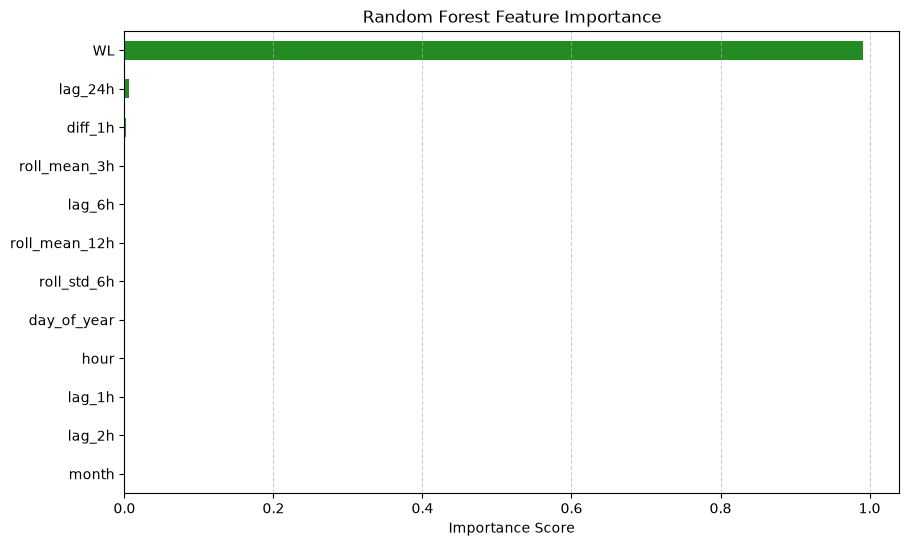

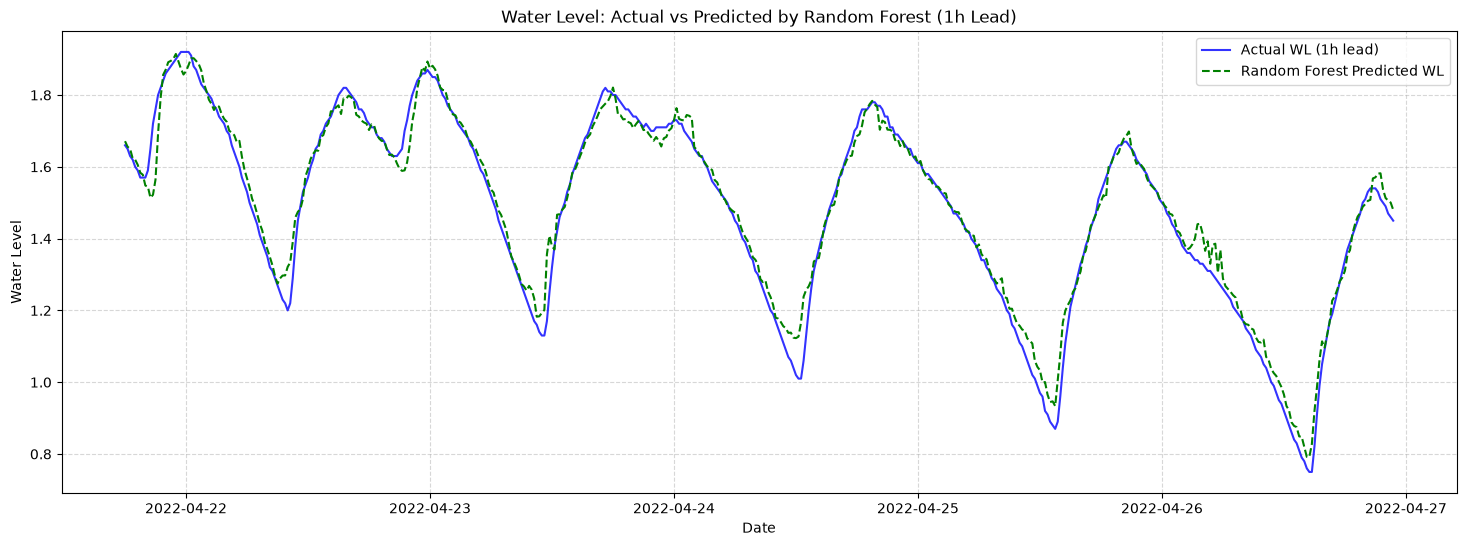

In [7]:
# 1. Feature Importances
importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values()

plt.figure(figsize=(10, 6))
importances.plot(kind="barh", color="forestgreen")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.show()

# 2. Actual vs Predicted (Zoomed in on the last 500 test steps for clarity)
plt.figure(figsize=(18, 6))
plt.plot(dates_test.iloc[-500:], y_test.iloc[-500:], label="Actual WL (1h lead)", color="blue", alpha=0.8)
plt.plot(dates_test.iloc[-500:], rf_preds[-500:], label="Random Forest Predicted WL", color="green", linestyle="--")
plt.xlabel("Date")
plt.ylabel("Water Level")
plt.title("Water Level: Actual vs Predicted by Random Forest (1h Lead)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()